# Nonlinear BVP

## Problem
$$
y'' = \tfrac{3}{2} y^2, \quad 0<x<1, \quad y(0)=4, \quad y(1)=1
$$
Exact solution $y = 4/(1+x)^2$.

## Discretization
The residual at node $i$ is

$$
F_i = \frac{y_{i-1} - 2y_i + y_{i+1}}{h^2} - \tfrac{3}{2} y_i^2
$$

The Jacobian is tridiagonal with diagonal $-2/h^2 - 3y_i$ and off-diagonals $1/h^2$. Newton starts from the straight line between the boundary values.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from fd_ode import newton_bvp

In [2]:
ex = lambda x: 4/(1+x)**2

In [3]:
x, y, res = newton_bvp(40, 4, 1)
for k, r in enumerate(res):
    print(f"iter {k}, res = {r:.3e}")

iter 0, res = 2.311e+01
iter 1, res = 7.721e-01
iter 2, res = 2.799e-03
iter 3, res = 3.570e-08
iter 4, res = 9.202e-13


### Newton residuals

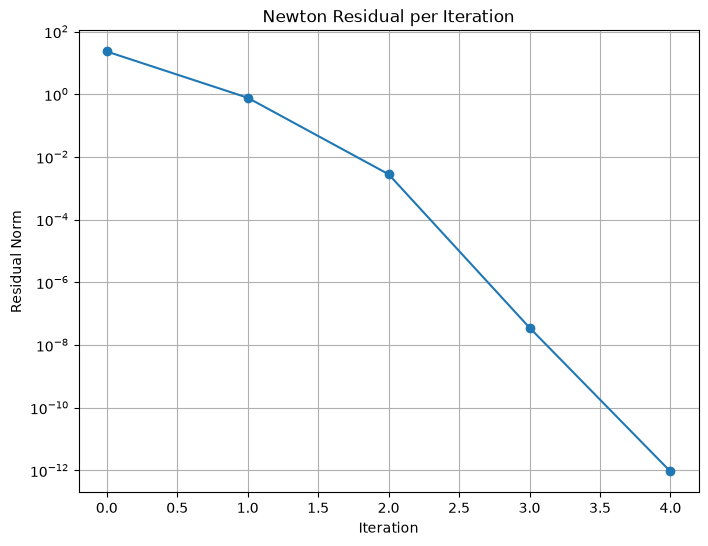

In [4]:
plt.figure(figsize=(8, 6))
plt.semilogy(res, 'o-')
plt.xlabel("Iteration")
plt.ylabel("Residual Norm")
plt.title("Newton Residual per Iteration")
plt.grid(True)
plt.savefig("../figures/02_newton_residual.png", dpi=300, bbox_inches="tight")
plt.show()

### Convergence

In [5]:
results = []
for N in [10, 20, 40, 80]:
    x, y, res = newton_bvp(N, 4, 1)
    e = np.linalg.norm(y-ex(x), np.inf)
    results.append({'h': 1/N, 'err': e, 'iters': len(res)-1})
df = pd.DataFrame(results)
df['order'] = np.log2(df['err'].shift()/df['err'])
df

,h,err,iters,order
0,0.1000,0.004697,4,NaN
1,0.0500,0.001190,4,1.981327
2,0.0250,0.000298,4,1.995224
3,0.0125,0.000075,4,1.997765


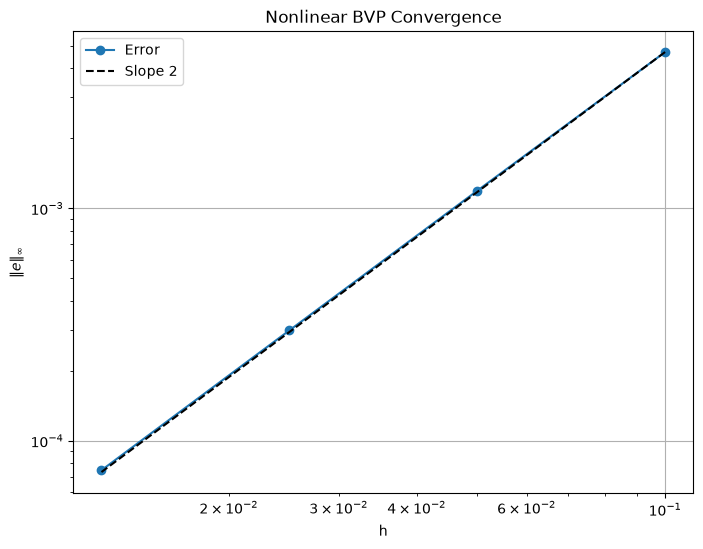

In [6]:
h = df['h'].values
plt.figure(figsize=(8, 6))
plt.loglog(h, df['err'], 'o-', label="Error")
plt.loglog(h, df['err'][0]*(h/h[0])**2, 'k--', label="Slope 2")
plt.xlabel("h")
plt.ylabel(r"$\|e\|_\infty$")
plt.title("Nonlinear BVP Convergence")
plt.legend()
plt.grid(True)
plt.savefig("../figures/02_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

### Second solution
The guess $4 - 3x - c\sin(\pi x)$ with larger $c$ lands on a different branch.

In [7]:
for c in range(16):
    xs, ys, rs = newton_bvp(40, 4, 1, y0=lambda x: 4-3*x-c*np.sin(np.pi*x))
    e = np.linalg.norm(ys-ex(xs), np.inf)
    print(f"c = {c}, res = {rs[-1]:.2e}, err = {e:.3e}")
    if rs[-1] < 1e-8 and e > 1:
        break

c = 0, res = 9.20e-13, err = 2.984e-04
c = 1, res = 2.46e-11, err = 2.984e-04
c = 2, res = 6.55e-13, err = 2.984e-04
c = 3, res = 9.20e-13, err = 2.984e-04
c = 4, res = 4.90e-12, err = 2.984e-04
c = 5, res = 8.60e-13, err = 2.984e-04
c = 6, res = 5.23e-12, err = 2.984e-04
c = 7, res = 4.15e-12, err = 1.238e+01


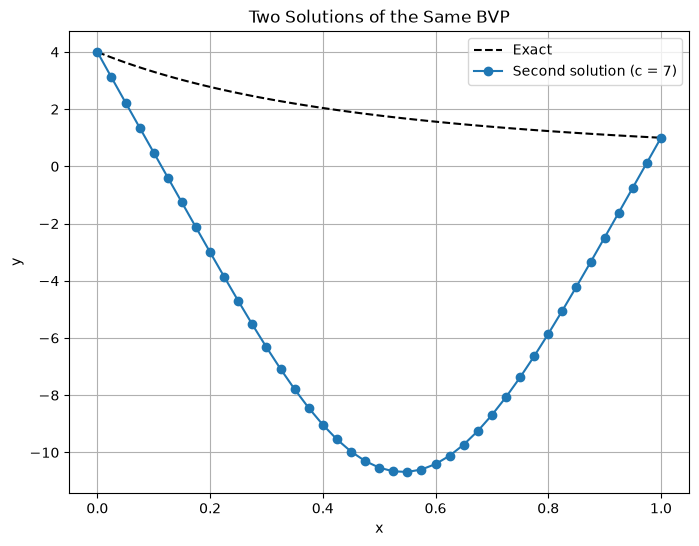

In [8]:
plt.figure(figsize=(8, 6))
plt.plot(x, ex(x), 'k--', label="Exact")
plt.plot(xs, ys, 'o-', label=f"Second solution (c = {c})")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Two Solutions of the Same BVP")
plt.legend()
plt.grid(True)
plt.savefig("../figures/02_second_solution.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
Newton converges in 4 iterations because the residual drops from about 2e1 to 1e-12 with each step roughly squaring the last one. The error is O(h^2), and the guess with c = 7 ends up on the second solution.